# Quantum Exam Scheduler: Track 2 Open-Domain Optimisation

## Problem Statement
University exam scheduling is an NP-hard combinatorial optimisation problem. Given a set of academic courses and student course enrollments, the goal is to assign each course an exam timeslot such that:
1. **Hard Constraints (Feasibility):** No two courses sharing enrolled students are scheduled in the same timeslot, and every course receives exactly one timeslot.
2. **Soft Objectives (Timetabling Preference):** Courses with large student enrollments are prioritized into earlier exam timeslots to allow more grading turnaround time.

## What This Notebook Demonstrates
- Formulation of timetabling as Graph Colouring and Quadratic Unconstrained Binary Optimisation (QUBO).
- Mapping of binary quadratic cost Hamiltonians to Pauli $Z$ and $ZZ$ Ising spin operators.
- Classical heuristics (Greedy Largest-First and DSATUR) and classical Exact exhaustive search.
- Implementation of the Quantum Approximate Optimisation Algorithm (QAOA) via Qiskit 2.5.2.
- Rigorous statistical benchmarking, parameter sweep sensitivity, and classical vs quantum trade-offs.

> **Honesty Box & Technical Disclaimer:**
> All quantum executions in this notebook are noiseless classical simulations executed via Statevector and Qiskit Aer Sampler. > Classical exact search solves this problem orders of magnitude faster. > **No quantum advantage, quantum speed-up, or commercial supremacy is claimed.**

## 1. Environment Setup & Dependency Configuration

We configure the runtime path, suppress non-critical deprecation notices, and record pinned library versions for reproducible execution.

*Technical Note:* Qiskit's `QAOAAnsatz` internally uses classes deprecated in Qiskit 2.1 (scheduled for removal in Qiskit 3.0). These warnings are filtered to ensure clean outputs on Qiskit 2.5.2.

In [1]:
%matplotlib inline
import sys
import os
import json
import warnings
from pathlib import Path

# Ensure project src directory is importable
sys.path.insert(0, '../src')

# Suppress known Qiskit 2.1 internal deprecation warnings from QAOAAnsatz
warnings.filterwarnings('ignore', category=DeprecationWarning)
warnings.filterwarnings('ignore', message='.*NLocal.*')
warnings.filterwarnings('ignore', message='.*BlueprintCircuit.*')

import platform
import numpy as np
import pandas as pd
import scipy
import networkx as nx
import matplotlib.pyplot as plt
import qiskit
import qiskit_aer
from IPython.display import Image, display

from exam_scheduler.data import DEFAULT_SEED, ExamInstance, sample_instance, ring_instance
from exam_scheduler.conflict_graph import build_conflict_graph, draw_conflict_graph, clique_lower_bound
from exam_scheduler.classical import greedy_schedule, exact_schedule, random_sampling_schedule
from exam_scheduler.validator import validate_schedule, schedule_objective
from exam_scheduler.qubo import build_qubo, decode_bits, qubo_energies_all, valid_state_mask, bitstring_to_bits
from exam_scheduler.ising import qubo_to_ising, ising_energies_all
from exam_scheduler.qaoa_solver import qaoa_schedule
from exam_scheduler.app_helpers import timetable_dataframe, top_counts_dataframe

print('=== Environment Dependency Versions ===')
print(f'Python:     {platform.python_version()}')
print(f'Qiskit:     {qiskit.__version__}')
print(f'Qiskit Aer: {qiskit_aer.__version__}')
print(f'NumPy:      {np.__version__}')
print(f'SciPy:      {scipy.__version__}')
print(f'NetworkX:   {nx.__version__}')
print(f'Pandas:     {pd.__version__}')

=== Environment Dependency Versions ===
Python:     3.13.5
Qiskit:     2.5.2
Qiskit Aer: 0.17.2
NumPy:      2.5.3
SciPy:      1.18.1
NetworkX:   3.7
Pandas:     3.0.6


## 2. Problem Instance Representation & Conflict Data

An exam instance contains courses, student enrollments, and enrollment overlap. Here we inspect the course directory and plot the shared-students conflict matrix. The headline dataset used for demonstration is synthetic.

Courses: 5 | Unique Students: 131 | Total Enrollments: 175

Course Directory Table:
 course  code                    title  students  weight
      0 CS101 Programming Fundamentals        40     0.8
      1 MA101                 Calculus        30     0.6
      2 PH101      Engineering Physics        50     1.0
      3 CS201          Data Structures        20     0.4
      4 EE101        Basic Electronics        35     0.7


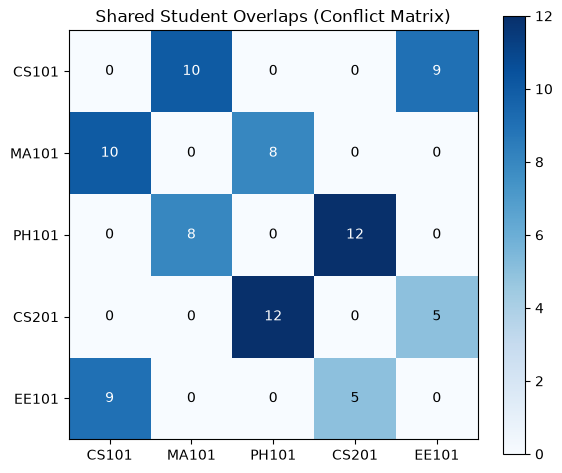

In [2]:
inst = sample_instance()
print(f'Courses: {inst.n_courses} | Unique Students: {inst.n_students} | Total Enrollments: {len(inst.enrollments)}')
print('\nCourse Directory Table:')
print(inst.course_table().to_string(index=False))

# Plot annotated shared-students matrix heatmap
shared_mat = inst.shared_students()
fig, ax = plt.subplots(figsize=(6, 5))
cax = ax.imshow(shared_mat, cmap='Blues')
fig.colorbar(cax, ax=ax)
ax.set_xticks(range(inst.n_courses))
ax.set_yticks(range(inst.n_courses))
ax.set_xticklabels(inst.course_codes)
ax.set_yticklabels(inst.course_codes)
for i in range(inst.n_courses):
    for j in range(inst.n_courses):
        val = shared_mat[i, j]
        color = 'white' if val > shared_mat.max() / 2 else 'black'
        ax.text(j, i, str(int(val)), ha='center', va='center', color=color)
ax.set_title('Shared Student Overlaps (Conflict Matrix)')
plt.tight_layout()
plt.show()

## 3. Conflict Graph Formulation & Lower Bounds

We construct an undirected conflict graph $G = (V, E)$, where each vertex represents a course and an edge exists between two courses whenever they share at least one student.

*Graph Theory Insight:* The chromatic number $\chi(G)$ (minimum slots needed for a valid schedule) is bounded below by the maximum clique size $\omega(G)$, because all courses in a mutual conflict clique must occupy pairwise distinct timeslots. Furthermore, odd cycle subgraphs cannot be colored with two slots, meaning an odd cycle requires more slots than bipartite coloring allows.

Graph Nodes: 5 | Graph Edges: 5
Maximum Clique Lower Bound on Slots: 2


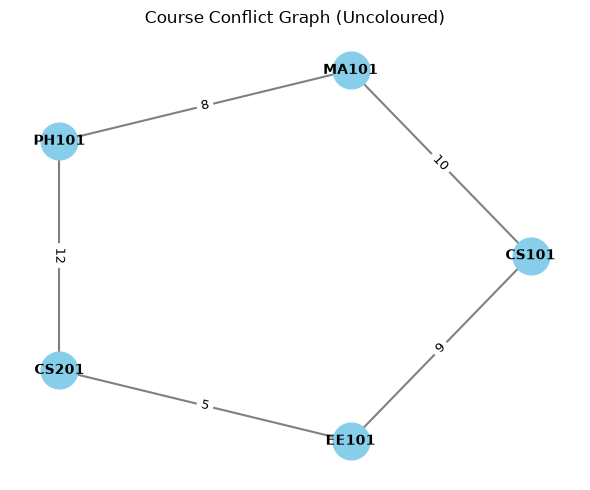

In [3]:
graph = build_conflict_graph(inst)
bound = clique_lower_bound(graph)
print(f'Graph Nodes: {graph.number_of_nodes()} | Graph Edges: {graph.number_of_edges()}')
print(f'Maximum Clique Lower Bound on Slots: {bound}')

fig, ax = plt.subplots(figsize=(6, 5))
draw_conflict_graph(graph, ax=ax, title='Course Conflict Graph (Uncoloured)')
plt.tight_layout()
plt.show()

## 4. Classical Heuristics & Exact Search Baselines

We evaluate classical graph coloring heuristics: **Largest First** (ordering by degree) and **DSATUR** (ordering dynamically by degree of saturation), alongside **Exact Exhaustive Search**.

We solve for both a feasible slot budget ($K=3$) and an intentionally restricted budget ($K=2$) to demonstrate independent validator diagnostics.

=== Classical Solver Benchmark (K = 3) ===
                Method  Valid  Slots Used Objective Optimality Gap Runtime (s)
          Exact Search   True           3    2.1000           0.0%     0.00022
Greedy (Largest First)   True           3    2.4000          14.3%     0.00027
       Greedy (DSATUR)   True           3    2.4000          14.3%     0.00009

Optimal Exam Timetable (Exact Solver):
             slot      courses  students
Slot 0 (earliest) CS101, PH101        90
           Slot 1 MA101, EE101        65
           Slot 2        CS201        20


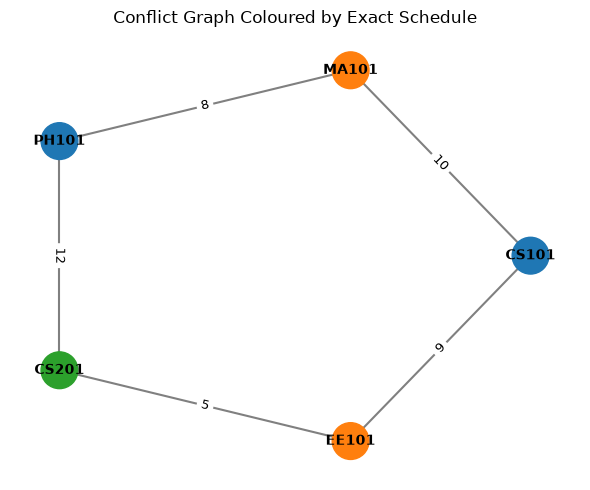

In [4]:
# Evaluate classical solvers for K = 3 slots
res_exact = exact_schedule(inst, n_slots=3)
res_glf = greedy_schedule(inst, n_slots=3, strategy='largest_first')
res_gds = greedy_schedule(inst, n_slots=3, strategy='DSATUR')

exact_opt = res_exact.objective
results_k3 = [
    {
        'Method': 'Exact Search',
        'Valid': res_exact.is_valid,
        'Slots Used': res_exact.slots_used,
        'Objective': f'{res_exact.objective:.4f}',
        'Optimality Gap': f'{(res_exact.objective - exact_opt)/exact_opt*100:.1f}%',
        'Runtime (s)': f'{res_exact.runtime_s:.5f}',
    },
    {
        'Method': 'Greedy (Largest First)',
        'Valid': res_glf.is_valid,
        'Slots Used': res_glf.slots_used,
        'Objective': f'{res_glf.objective:.4f}',
        'Optimality Gap': f'{(res_glf.objective - exact_opt)/exact_opt*100:.1f}%',
        'Runtime (s)': f'{res_glf.runtime_s:.5f}',
    },
    {
        'Method': 'Greedy (DSATUR)',
        'Valid': res_gds.is_valid,
        'Slots Used': res_gds.slots_used,
        'Objective': f'{res_gds.objective:.4f}',
        'Optimality Gap': f'{(res_gds.objective - exact_opt)/exact_opt*100:.1f}%',
        'Runtime (s)': f'{res_gds.runtime_s:.5f}',
    },
]
print('=== Classical Solver Benchmark (K = 3) ===')
print(pd.DataFrame(results_k3).to_string(index=False))

# Display timetable for optimal schedule
tt_df = timetable_dataframe(inst, res_exact.assignment, 3)
print('\nOptimal Exam Timetable (Exact Solver):')
print(tt_df.to_string(index=False))

# Plot conflict graph colored by exact schedule
fig, ax = plt.subplots(figsize=(6, 5))
slot_map = {c: res_exact.assignment[c] for c in range(inst.n_courses)}
draw_conflict_graph(graph, slot_of=slot_map, ax=ax, title='Conflict Graph Coloured by Exact Schedule')
plt.tight_layout()
plt.show()

### Infeasibility Verification at Restricted Budget ($K=2$)

Because the maximum clique size exceeds the slot budget, no conflict-free assignment exists at $K=2$. We verify that both exact search and greedy heuristics fail validation.

In [5]:
res_exact_k2 = exact_schedule(inst, n_slots=2)
res_greedy_k2 = greedy_schedule(inst, n_slots=2, strategy='largest_first')
print(f'Exact search valid at K=2: {res_exact_k2.is_valid} (assignment: {res_exact_k2.assignment})')
print(f'Greedy search valid at K=2: {res_greedy_k2.is_valid}')

val_k2 = validate_schedule(inst, res_greedy_k2.assignment, 2)
print('Validator diagnostics for Greedy at K=2:')
for msg in val_k2.messages:
    print(f'  - {msg}')

Exact search valid at K=2: False (assignment: None)
Greedy search valid at K=2: False
Validator diagnostics for Greedy at K=2:
  - course 4 (EE101) has slot 2 outside 0..1


## 5. QUBO Formulation & Constraint Penalty Analysis

To formulate exam scheduling for quantum optimization, we map decisions to binary variables $x_{c,t} \in \{0, 1\}$, where $x_{c,t} = 1$ indicates course $c$ is scheduled in timeslot $t$.

The objective energy function balances hard constraints against scheduling preferences:

$$E(x) = A \sum_{c} \left( \sum_{t} x_{c,t} - 1 \right)^2 + B \sum_{(i,j) \in E} \sum_{t} x_{i,t} x_{j,t} + \sum_{c} \sum_{t} w_c \cdot t \cdot x_{c,t}$$

- **Term 1 (One-Hot Penalty $A$):** Penalizes any course assigned to zero or multiple slots.
- **Term 2 (Conflict Penalty $B$):** Penalizes conflicting courses assigned to identical slots.
- **Term 3 (Soft Objective):** Minimizes total enrollment-weighted slot indices.

*Penalty Trade-Off Note:* The penalty parameters $A$ and $B$ must be large enough that invalid configurations have strictly higher energy than the optimal valid configuration. However, if a penalty is just large enough at the boundary threshold, an invalid configuration can tie in energy with the best valid schedule, causing the ground state manifold to contain multiple degenerate states, some of which may be invalid.

QUBO Binary Variables: 15
Upper-Triangular Matrix Shape: (15, 15)


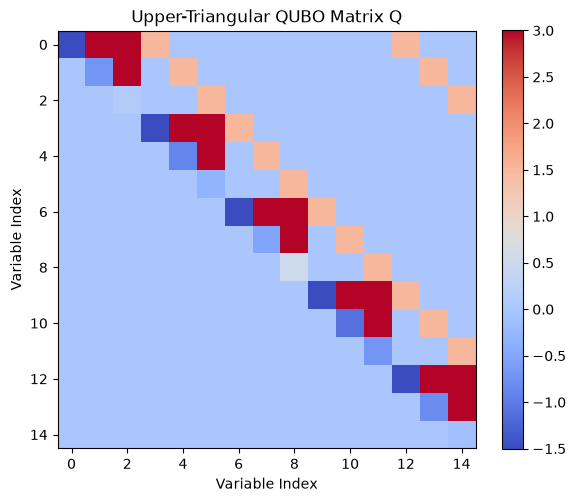

Feasible bitstrings in full state space: 30 / 32768 (0.0916%)
Ground State Energy: 2.1000 | Ground State Count: 1 | All Ground States Valid: True


In [6]:
model = build_qubo(inst, n_slots=3, penalty_one_hot=1.5, penalty_conflict=1.5)
print(f'QUBO Binary Variables: {model.n_vars}')
print(f'Upper-Triangular Matrix Shape: {model.Q.shape}')

# Heatmap of upper-triangular QUBO matrix
fig, ax = plt.subplots(figsize=(6, 5))
cax = ax.imshow(model.Q, cmap='coolwarm')
fig.colorbar(cax, ax=ax)
ax.set_title('Upper-Triangular QUBO Matrix Q')
ax.set_xlabel('Variable Index')
ax.set_ylabel('Variable Index')
plt.tight_layout()
plt.show()

# Exhaustive state-space brute-force scan
energies = qubo_energies_all(model)
mask = valid_state_mask(inst, n_slots=3)
f_count = int(mask.sum())
total_states = len(mask)
pct_feasible = (f_count / total_states) * 100.0
print(f'Feasible bitstrings in full state space: {f_count} / {total_states} ({pct_feasible:.4f}%)')

min_e = energies.min()
ground_indices = np.where(np.isclose(energies, min_e, atol=1e-9))[0]
all_valid = bool(mask[ground_indices].all())
print(f'Ground State Energy: {min_e:.4f} | Ground State Count: {len(ground_indices)} | All Ground States Valid: {all_valid}')

### Penalty Multiplier Sweep ($A = B$)

We evaluate the sensitivity of ground state validity across a spectrum of constraint penalties.

In [7]:
penalty_values = (1.0, 1.1, 1.15, 1.5, 2.0, 3.0)
sweep_rows = []

for pen in penalty_values:
    m_pen = build_qubo(inst, n_slots=3, penalty_one_hot=pen, penalty_conflict=pen)
    e_pen = qubo_energies_all(m_pen)
    min_val = e_pen.min()
    g_idx = np.where(np.isclose(e_pen, min_val, atol=1e-9))[0]
    is_all_valid = bool(mask[g_idx].all())
    sweep_rows.append({
        'Penalty (A=B)': f'{pen:.2f}',
        'Ground Energy': f'{min_val:.4f}',
        'Ground States Count': len(g_idx),
        'All Ground States Valid': is_all_valid,
    })

print('=== Penalty Multiplier Parameter Sweep ===')
print(pd.DataFrame(sweep_rows).to_string(index=False))

=== Penalty Multiplier Parameter Sweep ===
Penalty (A=B) Ground Energy  Ground States Count  All Ground States Valid
         1.00        2.0000                    3                    False
         1.10        2.1000                    4                    False
         1.15        2.1000                    1                     True
         1.50        2.1000                    1                     True
         2.00        2.1000                    1                     True
         3.00        2.1000                    1                     True


## 6. Ising Hamiltonian Mapping & Pauli Decomposition

To execute quantum algorithms, the QUBO is mapped to an Ising spin Hamiltonian using the standard variable transformation:

$$x_q = \frac{I - Z_q}{2}$$

where $Z_q$ is the Pauli-$Z$ operator acting on qubit $q$ with eigenvalues $\pm 1$. Under this mapping, diagonal QUBO terms become single-qubit $Z$ operators and off-diagonal terms become two-qubit $Z_i Z_j$ interaction terms.

*Qiskit Little-Endian Convention:* In Qiskit, measured bitstring strings are indexed right-to-left (the rightmost character represents qubit index 0). Our decoding function `bitstring_to_bits` explicitly reverses this string indexing to match variable indices.

In [8]:
ising = qubo_to_ising(model)
op = ising.operator
pauli_list = op.to_list()

z_terms = sum(1 for p, _ in pauli_list if p.count('Z') == 1)
zz_terms = sum(1 for p, _ in pauli_list if p.count('Z') == 2)
print(f'Total Pauli Hamiltonian Terms: {len(op)}')
print(f'Single-Qubit Z Terms:           {z_terms}')
print(f'Two-Qubit ZZ Interaction Terms: {zz_terms}')

print('\nFirst 8 Pauli Terms in Cost Operator:')
for label, coeff in pauli_list[:8]:
    print(f'  {label} : {coeff.real:+.4f}')

# Verify mathematical equivalence across all 2^N statevectors
i_energies = ising_energies_all(ising)
assert np.allclose(i_energies, energies)
print('\nIsing spectrum identically matches QUBO energy across all 2^N states: True')

# Demonstrate little-endian bitstring indexing
sample_str = '100'
sample_decoded = bitstring_to_bits(sample_str)
print(f"\nLittle-Endian demonstration: '{sample_str}' -> decoded bits: {sample_decoded} (qubit 0 is {sample_decoded[0]})")

Total Pauli Hamiltonian Terms: 46
Single-Qubit Z Terms:           15
Two-Qubit ZZ Interaction Terms: 30

First 8 Pauli Terms in Cost Operator:
  IIIIIIIIIIIIIIZ : -1.5000
  IIIIIIIIIIIIIZI : -1.9000
  IIIIIIIIIIIIZII : -2.3000
  IIIIIIIIIIIZIII : -1.5000
  IIIIIIIIIIZIIII : -1.8000
  IIIIIIIIIZIIIII : -2.1000
  IIIIIIIIZIIIIII : -1.5000
  IIIIIIIZIIIIIII : -2.0000

Ising spectrum identically matches QUBO energy across all 2^N states: True

Little-Endian demonstration: '100' -> decoded bits: [0, 0, 1] (qubit 0 is 0)


## 7. QAOA Variational Circuit Architecture & Memory Safety

The QAOA ansatz prepares an initial uniform superposition $|+\rangle^{\otimes N}$ via Hadamard gates, followed by alternating applications of the Cost unitary $U(C, \gamma) = e^{-i \gamma H_C}$ (built from $R_{ZZ}$ and $R_Z$ rotations) and the Mixer unitary $U(B, \beta) = e^{-i \beta H_M}$ ($R_X$ transverse field rotations) across $p$ layers.

> **Memory Guard Notice:** Passing an untranspiled `QAOAAnsatz` (containing high-level `PauliEvolutionGate` blocks) > directly to `StatevectorEstimator` causes Qiskit to construct a dense $2^N \times 2^N$ operator matrix. > For $N=15$ qubits, this consumes 16 GiB of RAM and causes process termination. > To prevent this, the circuit must always be transpiled into 1- and 2-qubit basis gates (`rz`, `sx`, `x`, `cx`) prior to simulation.

In [9]:
# Illustrate high-level and decomposed circuit structure on a smaller ring instance
from qiskit.circuit.library import QAOAAnsatz
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

small_inst = ring_instance(3, seed=DEFAULT_SEED)
small_model = build_qubo(small_inst, n_slots=3)
small_ising = qubo_to_ising(small_model)
small_ansatz = QAOAAnsatz(small_ising.operator, reps=1)

print(f'Illustrative Small Ring Instance Qubits: {small_ansatz.num_qubits}')
try:
    fig = small_ansatz.decompose().draw('mpl', fold=25)
    plt.show()
    print('Rendered circuit diagram using Matplotlib drawer.')
except Exception as e:
    print(f'Matplotlib drawer unavailable ({type(e).__name__}). Using text drawer:')
    print(small_ansatz.draw('text', fold=70))

# Transpilation statistics for headline instance (reps = 1 and reps = 2)
pm = generate_preset_pass_manager(optimization_level=1, basis_gates=['rz', 'sx', 'x', 'cx'], seed_transpiler=42)

head_ansatz_p1 = QAOAAnsatz(ising.operator, reps=1)
trans_p1 = pm.run(head_ansatz_p1)
ops_p1 = trans_p1.count_ops()
print(f'\nHeadline Instance QAOA (p=1): Depth={trans_p1.depth()} | CX Gates={ops_p1.get("cx", 0)}')
print(f'Parameters (p=1): {[p.name for p in trans_p1.parameters]}')

head_ansatz_p2 = QAOAAnsatz(ising.operator, reps=2)
trans_p2 = pm.run(head_ansatz_p2)
ops_p2 = trans_p2.count_ops()
print(f'\nHeadline Instance QAOA (p=2): Depth={trans_p2.depth()} | CX Gates={ops_p2.get("cx", 0)}')
print(f'Parameters (p=2): {[p.name for p in trans_p2.parameters]}')

Illustrative Small Ring Instance Qubits: 9
Matplotlib drawer unavailable (MissingOptionalLibraryError). Using text drawer:
     ┌──────────────────┐
q_0: ┤0                 ├
     │                  │
q_1: ┤1                 ├
     │                  │
q_2: ┤2                 ├
     │                  │
q_3: ┤3                 ├
     │                  │
q_4: ┤4 QAOA(γ[0],β[0]) ├
     │                  │
q_5: ┤5                 ├
     │                  │
q_6: ┤6                 ├
     │                  │
q_7: ┤7                 ├
     │                  │
q_8: ┤8                 ├
     └──────────────────┘

Headline Instance QAOA (p=1): Depth=66 | CX Gates=60
Parameters (p=1): ['β[0]', 'γ[0]']



Headline Instance QAOA (p=2): Depth=87 | CX Gates=120
Parameters (p=2): ['β[0]', 'β[1]', 'γ[0]', 'γ[1]']


## 8. Live QAOA Execution & Measurement Sampling ($p=1$)

We optimize the variational angles $\beta$ and $\gamma$ using the classical COBYLA optimizer with multiple random restarts to mitigate local minima. Following convergence, the optimal state is sampled with 4,096 measurement shots.

QAOA Solved: Best Restart=1 | Final Energy=14.8402
  Restart 0: Final <H_C> = 17.4137 (58 evals)
  Restart 1: Final <H_C> = 14.8402 (42 evals)
  Restart 2: Final <H_C> = 15.6160 (48 evals)


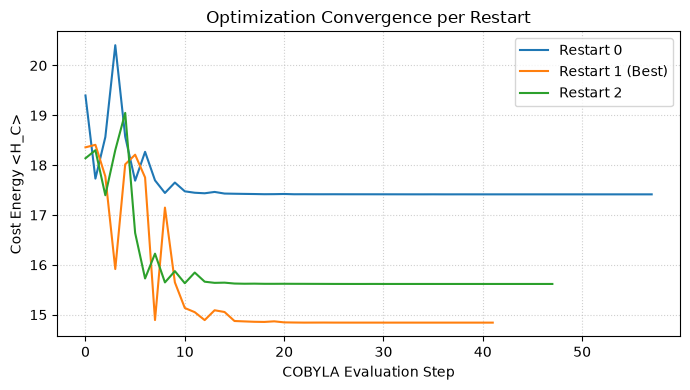


Top 15 Measured Bitstrings:
      bitstring  count  share_pct  valid    schedule
010100010100010     28   0.683594  False   1 2 1 2 1
110100010110010     24   0.585938  False not one-hot
000100010100010     21   0.512695  False not one-hot
110100010100010     19   0.463867  False not one-hot
011100010100010     18   0.439453  False not one-hot
010100011100010     17   0.415039  False not one-hot
110100010101010     17   0.415039  False not one-hot
111100010100010     17   0.415039  False not one-hot
000100010100011     16   0.390625  False not one-hot
010100010100000     16   0.390625  False not one-hot
010100010101010     16   0.390625  False not one-hot
010100010110010     15   0.366211  False not one-hot
110100010100011     14   0.341797  False not one-hot
100100010110010     13   0.317383  False not one-hot
110100110100010     13   0.317383  False not one-hot


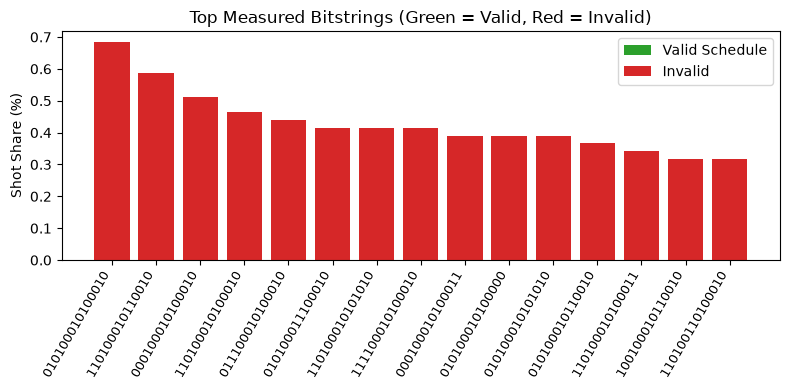

Exact Feasible Probability (Statevector): 0.5098%
Shot Feasibility Yield (Measured):        0.5615% (23/4096 shots)
Uniform Random-Guess Probability:         0.0916%
Best Valid Schedule: [1, 0, 1, 2, 0] | Objective: 2.6000


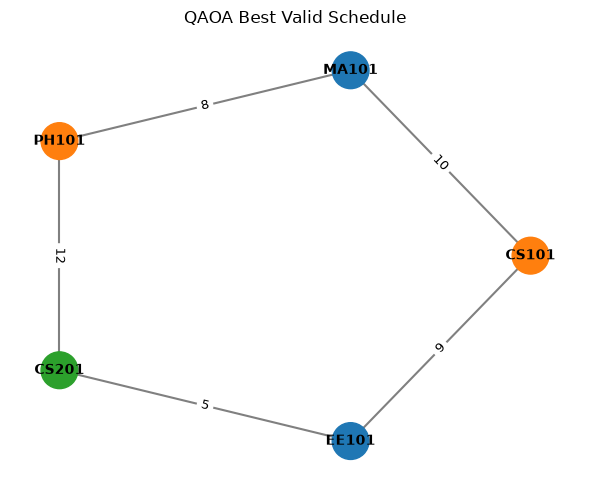

In [10]:
q_outcome = qaoa_schedule(
    inst,
    n_slots=3,
    reps=1,
    n_restarts=3,
    shots=4096,
    maxiter=150,
    seed=42,
)

print(f'QAOA Solved: Best Restart={q_outcome.best_restart} | Final Energy={q_outcome.final_energy:.4f}')
for r_info in q_outcome.restarts:
    print(f"  Restart {r_info['restart']}: Final <H_C> = {r_info['final_energy']:.4f} ({r_info['n_evaluations']} evals)")

# Convergence plot across restarts
fig, ax = plt.subplots(figsize=(7, 4))
for r_info in q_outcome.restarts:
    r_idx = r_info['restart']
    hist = r_info.get('history', [])
    label = f"Restart {r_idx}" + (' (Best)' if r_idx == q_outcome.best_restart else '')
    ax.plot(hist, label=label, linewidth=1.5)
ax.set_xlabel('COBYLA Evaluation Step')
ax.set_ylabel('Cost Energy <H_C>')
ax.set_title('Optimization Convergence per Restart')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend()
plt.tight_layout()
plt.show()

# Inspect top measured bitstrings
top_df = top_counts_dataframe(inst, 3, q_outcome.counts, top=15)
print('\nTop 15 Measured Bitstrings:')
print(top_df.to_string(index=False))

# Bar chart of top bitstrings coloured by validity
fig, ax = plt.subplots(figsize=(8, 4))
colors = ['#2ca02c' if v else '#d62728' for v in top_df['valid']]
ax.bar(range(len(top_df)), top_df['share_pct'], color=colors)
ax.set_xticks(range(len(top_df)))
ax.set_xticklabels(top_df['bitstring'], rotation=60, ha='right', fontsize=9)
ax.set_ylabel('Shot Share (%)')
ax.set_title('Top Measured Bitstrings (Green = Valid, Red = Invalid)')
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#2ca02c', label='Valid Schedule'), Patch(facecolor='#d62728', label='Invalid')]
ax.legend(handles=legend_elements)
plt.tight_layout()
plt.show()

# Feasibility comparison
print(f'Exact Feasible Probability (Statevector): {q_outcome.exact_feasible_probability * 100:.4f}%')
print(f'Shot Feasibility Yield (Measured):        {q_outcome.feasibility_yield * 100:.4f}% ({q_outcome.n_valid_shots}/{q_outcome.shots} shots)')
print(f'Uniform Random-Guess Probability:         {q_outcome.random_guess_probability * 100:.4f}%')

if q_outcome.result.is_valid and q_outcome.result.assignment is not None:
    val = validate_schedule(inst, q_outcome.result.assignment, 3)
    print(f'Best Valid Schedule: {q_outcome.result.assignment} | Objective: {q_outcome.result.objective:.4f}')
    fig, ax = plt.subplots(figsize=(6, 5))
    slot_map_q = {c: q_outcome.result.assignment[c] for c in range(inst.n_courses)}
    draw_conflict_graph(graph, slot_of=slot_map_q, ax=ax, title='QAOA Best Valid Schedule')
    plt.tight_layout()
    plt.show()
else:
    print('No valid schedule was found in the measured shots.')

## 9. Head-to-Head Solver Comparison

We evaluate exact search, greedy heuristics, classical random sampling (with identical shot count and seed), and QAOA side-by-side on the headline problem instance.

In [11]:
res_rand = random_sampling_schedule(inst, n_slots=3, shots=4096, seed=42)

h2h_rows = [
    {
        'Method': 'Exact Search',
        'Valid': res_exact.is_valid,
        'Slots Used': res_exact.slots_used,
        'Objective': f'{res_exact.objective:.4f}',
        'Optimality Gap': f'{(res_exact.objective - exact_opt)/exact_opt*100:.1f}%',
        'Runtime (s)': f'{res_exact.runtime_s:.5f}',
    },
    {
        'Method': 'Greedy (Largest First)',
        'Valid': res_glf.is_valid,
        'Slots Used': res_glf.slots_used,
        'Objective': f'{res_glf.objective:.4f}',
        'Optimality Gap': f'{(res_glf.objective - exact_opt)/exact_opt*100:.1f}%',
        'Runtime (s)': f'{res_glf.runtime_s:.5f}',
    },
    {
        'Method': 'Greedy (DSATUR)',
        'Valid': res_gds.is_valid,
        'Slots Used': res_gds.slots_used,
        'Objective': f'{res_gds.objective:.4f}',
        'Optimality Gap': f'{(res_gds.objective - exact_opt)/exact_opt*100:.1f}%',
        'Runtime (s)': f'{res_gds.runtime_s:.5f}',
    },
    {
        'Method': 'Random Sampling (4096 shots)',
        'Valid': res_rand.is_valid,
        'Slots Used': res_rand.slots_used if res_rand.is_valid else '-',
        'Objective': f'{res_rand.objective:.4f}' if res_rand.objective is not None else '-',
        'Optimality Gap': f'{(res_rand.objective - exact_opt)/exact_opt*100:.1f}%' if res_rand.is_valid and res_rand.objective is not None else '-',
        'Runtime (s)': f'{res_rand.runtime_s:.5f}',
    },
    {
        'Method': 'QAOA (p=1, 4096 shots)',
        'Valid': q_outcome.result.is_valid,
        'Slots Used': q_outcome.result.slots_used if q_outcome.result.is_valid else '-',
        'Objective': f'{q_outcome.result.objective:.4f}' if q_outcome.result.objective is not None else '-',
        'Optimality Gap': f'{(q_outcome.result.objective - exact_opt)/exact_opt*100:.1f}%' if q_outcome.result.is_valid and q_outcome.result.objective is not None else '-',
        'Runtime (s)': f'{q_outcome.result.runtime_s:.5f}',
    },
]
print('=== Head-to-Head Solver Comparison Table ===')
print(pd.DataFrame(h2h_rows).to_string(index=False))

=== Head-to-Head Solver Comparison Table ===
                      Method  Valid  Slots Used Objective Optimality Gap Runtime (s)
                Exact Search   True           3    2.1000           0.0%     0.00022
      Greedy (Largest First)   True           3    2.4000          14.3%     0.00027
             Greedy (DSATUR)   True           3    2.4000          14.3%     0.00009
Random Sampling (4096 shots)   True           3    2.4000          14.3%     0.00042
      QAOA (p=1, 4096 shots)   True           3    2.6000          23.8%    12.84364


## 10. Multi-Run Benchmark Suite Results

To evaluate statistical reproducibility beyond single-seed runs, we load the precomputed benchmark suite across experiments E1 (headline), E2 (penalty sweep), and E3 (instance scaling).

=== Benchmark Summary Table ===
      experiment instance               method  reps  penalty  runs  n_valid_runs  valid_run_rate  mean_feasibility_yield  median_feasibility_yield  optimum_found_rate  mean_optimality_gap  mean_slots_used  median_runtime_s  min_runtime_s  max_runtime_s
     E1_headline   sample                exact   NaN      NaN     1             1            1.00                     NaN                       NaN            1.000000             0.000000         3.000000          0.000147       0.000147       0.000147
     E1_headline   sample        greedy-DSATUR   NaN      NaN     1             1            1.00                     NaN                       NaN            0.000000             0.142857         3.000000          0.000155       0.000155       0.000155
     E1_headline   sample greedy-largest_first   NaN      NaN     1             1            1.00                     NaN                       NaN            0.000000             0.142857         3.000000 

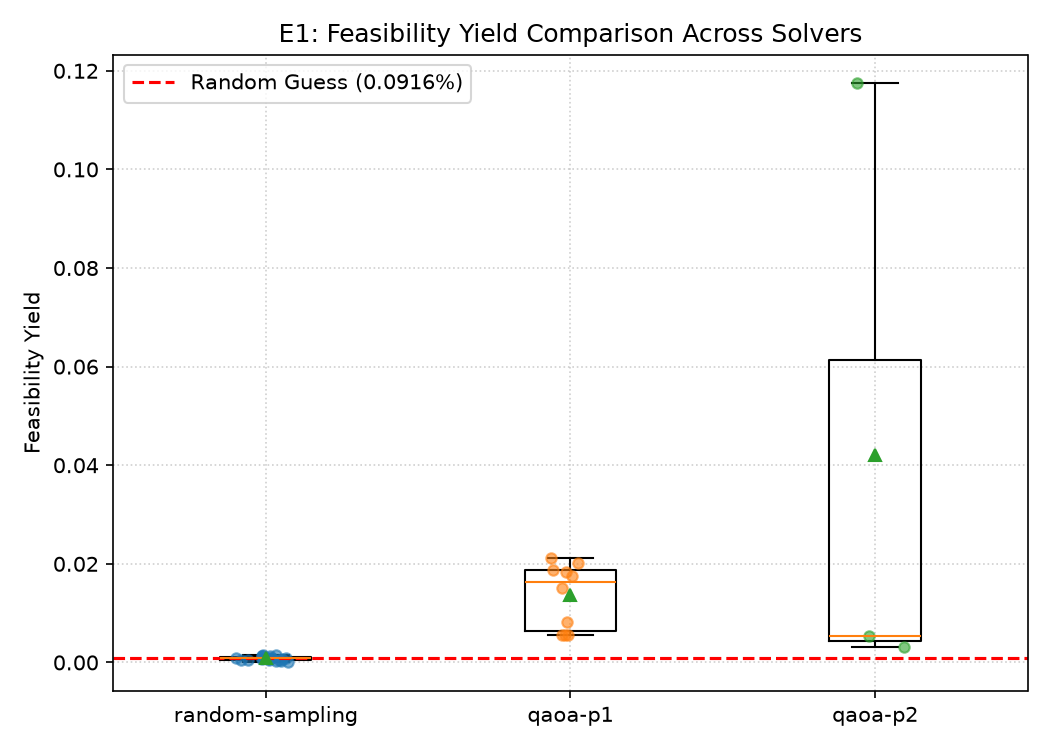

-- E1 Schedule Objective Distribution --


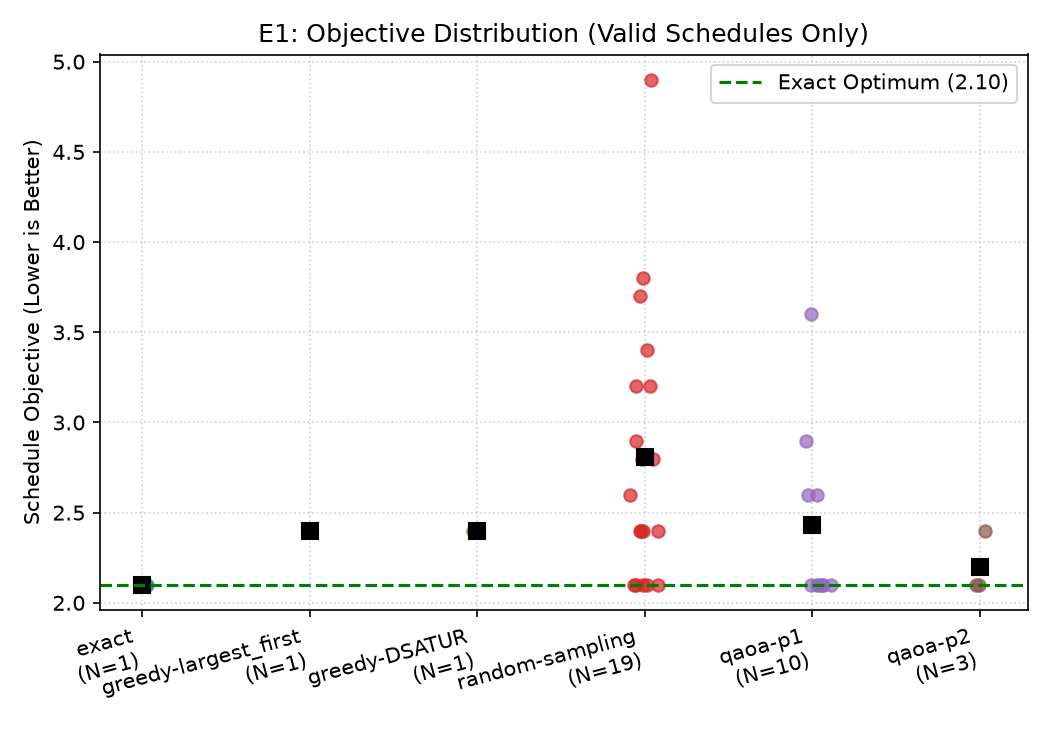

-- E2 Penalty Multiplier Sweep --


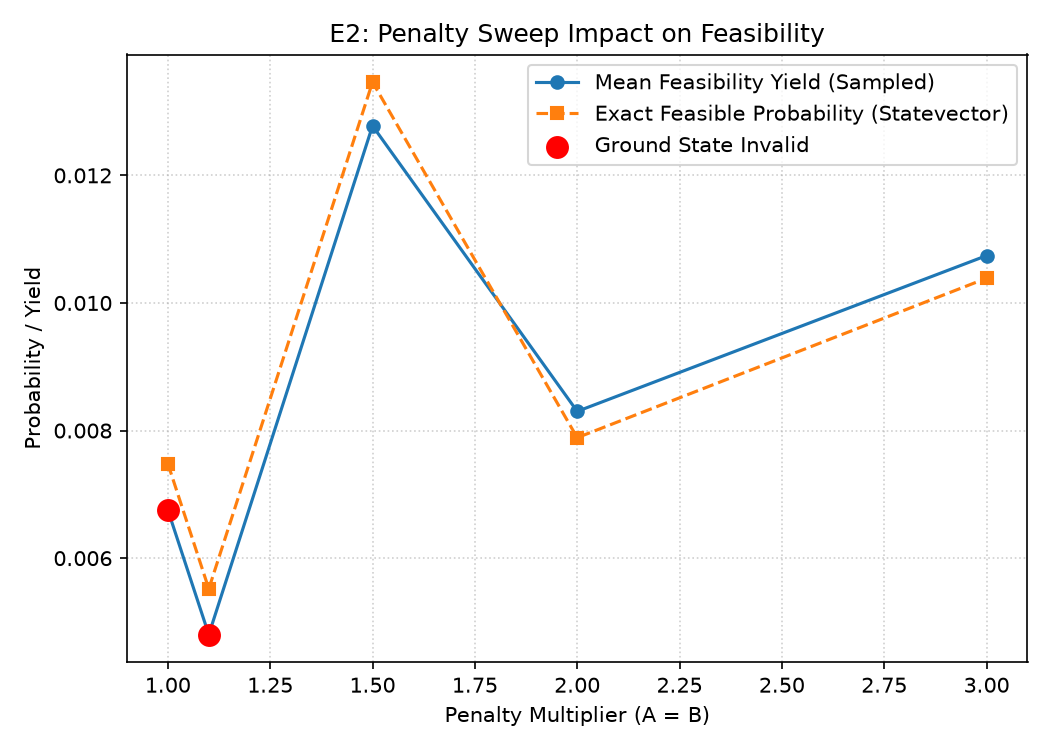

-- E3 Problem Scaling (Yield and Runtime) --


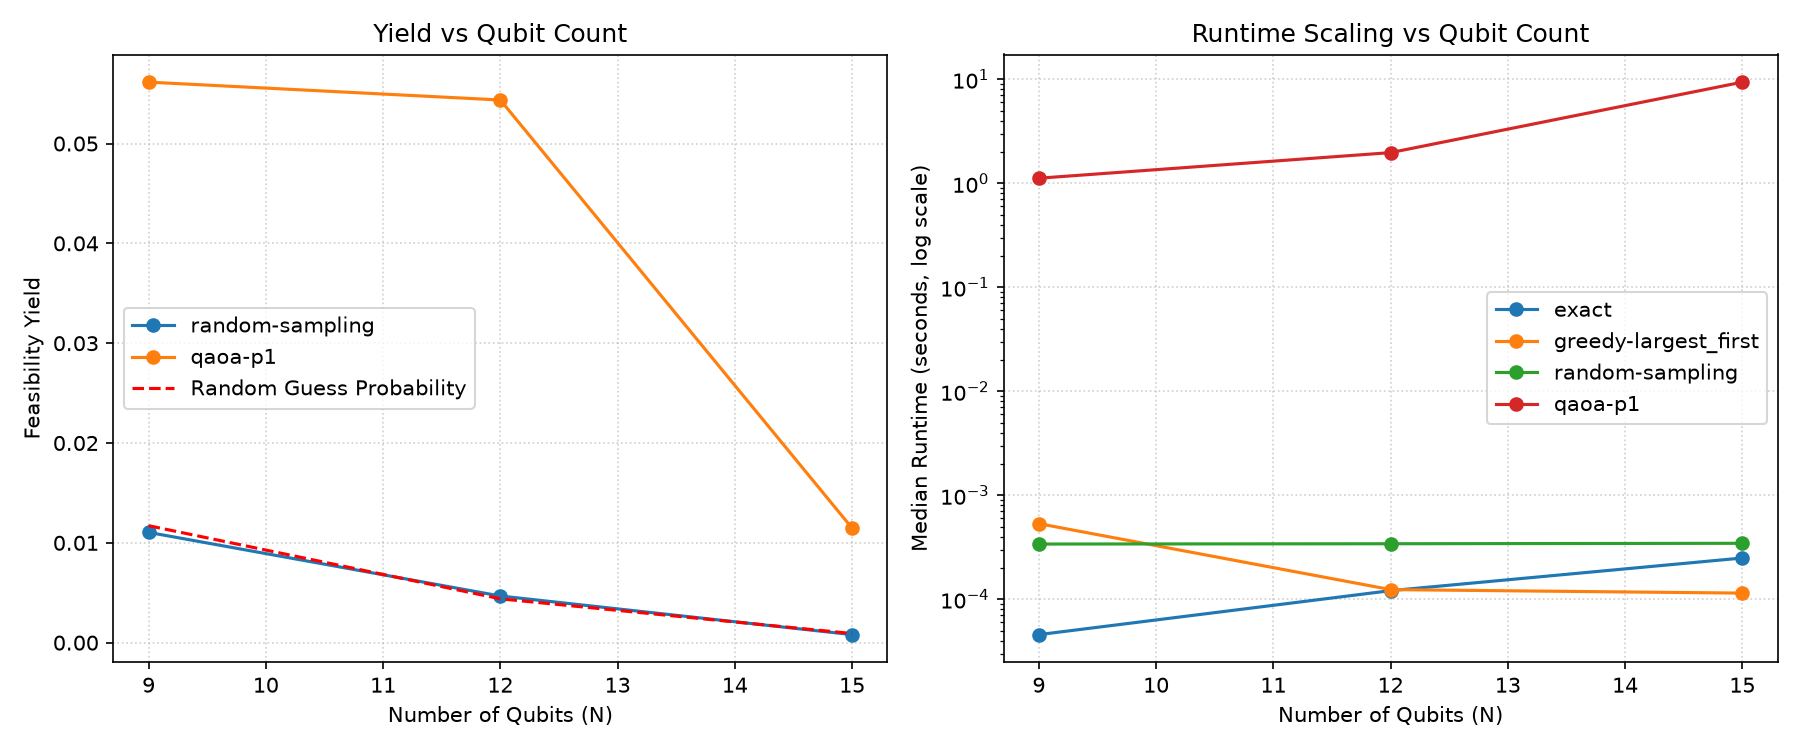


Benchmark Execution Metadata:
  platform: Windows-11-10.0.26300-SP0
  python_version: 3.13.5
  qiskit: 2.5.2
  qiskit_aer: 0.17.2
  timestamp_utc: 2026-10-11T06:27:50.903734+00:00


In [12]:
res_dir = Path('../results')
summary_csv = res_dir / 'benchmark_summary.csv'
meta_file = res_dir / 'benchmark_meta.json'

if summary_csv.exists():
    summary_df = pd.read_csv(summary_csv)
    print('=== Benchmark Summary Table ===')
    print(summary_df.to_string(index=False))

    print('\n=== Precomputed Benchmark Figures ===')
    for fname, title in [
        ('fig_feasibility.png', 'E1 Feasibility Yield Across Solvers'),
        ('fig_objective.png', 'E1 Schedule Objective Distribution'),
        ('fig_penalty.png', 'E2 Penalty Multiplier Sweep'),
        ('fig_scaling.png', 'E3 Problem Scaling (Yield and Runtime)'),
    ]:
        p = res_dir / fname
        if p.exists():
            print(f'-- {title} --')
            display(Image(filename=str(p)))

    if meta_file.exists():
        meta_data = json.loads(meta_file.read_text(encoding='utf-8'))
        print('\nBenchmark Execution Metadata:')
        for k in ['platform', 'python_version', 'qiskit', 'qiskit_aer', 'timestamp_utc']:
            print(f'  {k}: {meta_data.get(k)}')
else:
    print(f'Benchmark data not found in {res_dir}. Run: python src/main.py benchmark --out results')

## 10b. Statistical Significance Analysis: Are the Differences Meaningful?

To avoid misleading single-run claims, we analyze empirical distributions across repeated benchmark trials:
1. **Wilson Score Confidence Intervals (95%):** Provide coverage bounds for binomial proportions (valid run rate and optimum found rate) that remain well-calibrated even with small sample sizes.
2. **Fisher's Exact Test:** Evaluates whether differences in the proportion of runs finding the global optimum reach statistical significance ($p < 0.05$).
3. **Mann-Whitney $U$ Test:** Non-parametric rank-sum test evaluating whether the distribution of feasibility yields from QAOA is stochastically greater than uniform random sampling.

When confidence intervals overlap and sample sizes are small, differences cannot be deemed statistically conclusive.

In [13]:
runs_file = Path('../results/benchmark_runs.csv')
if runs_file.exists():
    runs_df = pd.read_csv(runs_file)
    e1_df = runs_df[runs_df['experiment'] == 'E1_headline']

    def wilson_ci(k, n, z=1.95996):
        if n == 0:
            return 0.0, 0.0, 0.0
        p_hat = k / n
        denom = 1.0 + (z**2) / n
        center = (p_hat + (z**2) / (2 * n)) / denom
        half = (z * np.sqrt((p_hat * (1.0 - p_hat) / n) + (z**2) / (4 * n**2))) / denom
        return p_hat, max(0.0, center - half), min(1.0, center + half)

    stat_rows = []
    for m in ['random-sampling', 'qaoa-p1', 'qaoa-p2']:
        m_df = e1_df[e1_df['method'] == m]
        if m_df.empty:
            continue
        n_runs = len(m_df)
        n_valid = int((m_df['is_valid'] == True).sum())
        opt_hits = m_df.apply(
            lambda r: bool(r['is_valid']) and pd.notna(r['optimal_objective']) and pd.notna(r['objective']) and abs(r['objective'] - r['optimal_objective']) < 1e-9,
            axis=1,
        )
        n_opt = int(opt_hits.sum())

        v_rate, v_lo, v_hi = wilson_ci(n_valid, n_runs)
        o_rate, o_lo, o_hi = wilson_ci(n_opt, n_runs)
        mean_yield = m_df['feasibility_yield'].mean() if m_df['feasibility_yield'].notna().any() else np.nan

        stat_rows.append({
            'Method': m,
            'Runs': n_runs,
            'Valid Runs': n_valid,
            'Valid Rate [95% CI]': f'{v_rate*100:.1f}% [{v_lo*100:.1f}%, {v_hi*100:.1f}%]',
            'Optimum Hits': n_opt,
            'Optimum Rate [95% CI]': f'{o_rate*100:.1f}% [{o_lo*100:.1f}%, {o_hi*100:.1f}%]',
            'Mean Yield': f'{mean_yield*100:.2f}%' if pd.notna(mean_yield) else '-',
        })

    print('=== Statistical Confidence Intervals (E1 Headline) ===')
    print(pd.DataFrame(stat_rows).to_string(index=False))

    # Hypothesis tests comparing qaoa-p1 against random-sampling
    q1_data = e1_df[e1_df['method'] == 'qaoa-p1']
    rs_data = e1_df[e1_df['method'] == 'random-sampling']
    if not q1_data.empty and not rs_data.empty:
        q1_opt = int(q1_data.apply(lambda r: bool(r['is_valid']) and abs(r['objective'] - r['optimal_objective']) < 1e-9, axis=1).sum())
        q1_fail = len(q1_data) - q1_opt
        rs_opt = int(rs_data.apply(lambda r: bool(r['is_valid']) and abs(r['objective'] - r['optimal_objective']) < 1e-9, axis=1).sum())
        rs_fail = len(rs_data) - rs_opt

        odds_ratio, p_fisher = scipy.stats.fisher_exact([[q1_opt, q1_fail], [rs_opt, rs_fail]])
        print(f"\nFisher's Exact Test (Optimum Found Rate: qaoa-p1 vs random-sampling): p-value = {p_fisher:.4f} (odds ratio = {odds_ratio:.4f})")

        q1_yields = q1_data['feasibility_yield'].dropna()
        rs_yields = rs_data['feasibility_yield'].dropna()
        u_stat, p_mwu = scipy.stats.mannwhitneyu(q1_yields, rs_yields, alternative='greater')
        yield_ratio = q1_yields.mean() / rs_yields.mean() if rs_yields.mean() > 0 else np.nan
        print(f'Mann-Whitney U Test (Feasibility Yield: qaoa-p1 > random-sampling): p-value = {p_mwu:.4f} (U = {u_stat:.1f})')
        print(f'Ratio of Mean Feasibility Yield (qaoa-p1 / random-sampling): {yield_ratio:.2f}x')

    # Runtime scaling ratios relative to exact search
    exact_runs = e1_df[e1_df['method'] == 'exact']
    if not exact_runs.empty:
        exact_med_rt = exact_runs['runtime_s'].median()
        if not q1_data.empty:
            q1_med_rt = q1_data['runtime_s'].median()
            print(f'Ratio of Median Runtime (qaoa-p1 / exact solver): {q1_med_rt / exact_med_rt:.1f}x')
        q2_data = e1_df[e1_df['method'] == 'qaoa-p2']
        if not q2_data.empty:
            q2_med_rt = q2_data['runtime_s'].median()
            print(f'Ratio of Median Runtime (qaoa-p2 / exact solver): {q2_med_rt / exact_med_rt:.1f}x')

    # Random sampling empirical yield vs full state-space feasibility
    if not rs_data.empty:
        emp_yield = rs_data['feasibility_yield'].mean()
        true_prob = float(valid_state_mask(inst, 3).sum()) / (1 << 15)
        print(f'\nEmpirical Random-Sampling Yield:     {emp_yield*100:.4f}%')
        print(f'True State-Space Feasible Fraction:   {true_prob*100:.4f}%')
else:
    print(f'Benchmark runs file {runs_file} not found.')

=== Statistical Confidence Intervals (E1 Headline) ===
         Method  Runs  Valid Runs    Valid Rate [95% CI]  Optimum Hits Optimum Rate [95% CI] Mean Yield
random-sampling    20          19   95.0% [76.4%, 99.1%]             5  25.0% [11.2%, 46.9%]      0.08%
        qaoa-p1    10          10 100.0% [72.2%, 100.0%]             6  60.0% [31.3%, 83.2%]      1.36%
        qaoa-p2     3           3 100.0% [43.9%, 100.0%]             2  66.7% [20.8%, 93.9%]      4.20%



Fisher's Exact Test (Optimum Found Rate: qaoa-p1 vs random-sampling): p-value = 0.1081 (odds ratio = 4.5000)
Mann-Whitney U Test (Feasibility Yield: qaoa-p1 > random-sampling): p-value = 0.0000 (U = 200.0)
Ratio of Mean Feasibility Yield (qaoa-p1 / random-sampling): 16.94x
Ratio of Median Runtime (qaoa-p1 / exact solver): 55487.0x
Ratio of Median Runtime (qaoa-p2 / exact solver): 421195.4x

Empirical Random-Sampling Yield:     0.0806%
True State-Space Feasible Fraction:   0.0916%


Please inspect the table and statistical test outputs printed directly above for the confidence intervals, p-values, and runtime ratios. As shown in the outputs, with small sample sizes the confidence intervals overlap, meaning firm conclusions cannot be drawn regarding solver superiority.

## 11. Conclusions & Technical Limitations

### Key Findings
- **Feasibility Amplification:** Variational optimization via QAOA shifts state probabilities toward low-energy configurations, raising the per-shot share of valid schedules above uniform random guess levels. However, a majority of measured shots remain infeasible.
- **Validation Requirement:** Quantum solvers generate candidate solutions probabilistically; every schedule must undergo independent verification by the classical validator before acceptance.
- **Modal State vs Validity:** The single most frequent bitstring measured from QAOA is frequently invalid, requiring top-shot filtering across measured samples.
- **Classical vs Quantum Scalability:** On these small instances, classical exact search and greedy heuristics execute orders of magnitude faster than classical quantum simulation. No quantum advantage or speed-up is claimed.

### Practical Limitations
- **Simulation Overhead:** Classical simulation of quantum circuits scales exponentially with qubit count, restricting direct noiseless statevector study to modest problem sizes.
- **Classical Optimizer Sensitivity:** Optimization performance is sensitive to the COBYLA evaluation budget and initial random angle seeds.
- **Sample Size Constraints:** Modest seed counts yield overlapping confidence intervals, indicating exploratory rather than definitive statistical trends.
- **Noiseless Simulation:** Results reflect ideal mathematical operators; physical quantum processor noise (decoherence, crosstalk, gate infidelities) was not modeled.
- **QUBO Penalty Trade-offs:** Quadratic penalty coefficients require delicate tuning to balance constraint satisfaction against objective discrimination.